In [1]:
import sys
sys.path.append("..")
from src.data import load_data
from src.costs import expected_cost
X, y = load_data()

In [2]:
from src.data import NUMERIC, CATEGORICAL

print(X.shape, y.shape)
print("missing values:", int(X.isna().sum().sum()))
X.dtypes.value_counts()

(1000, 20) (1000,)
missing values: 0


object    13
int64      7
Name: count, dtype: int64

In [3]:
X[NUMERIC].describe().T
X[CATEGORICAL].nunique().sort_values()

foreign_worker              2
telephone                   2
other_debtors               3
housing                     3
other_installment_plans     3
checking_status             4
personal_status_sex         4
property                    4
job                         4
employment_since            5
savings                     5
credit_history              5
purpose                    10
dtype: int64

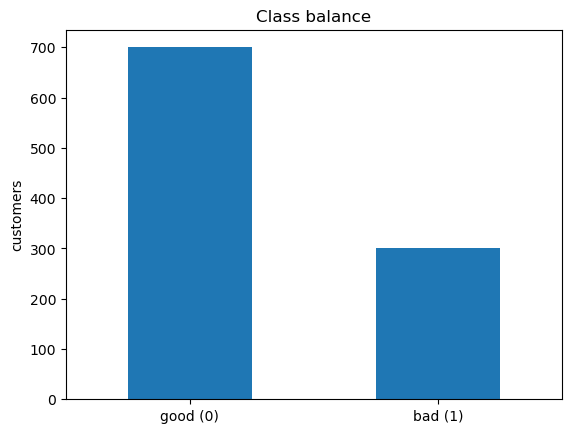

good (0)    700
bad (1)     300
Name: count, dtype: int64 
bad share: 0.3


In [4]:
import matplotlib.pyplot as plt

counts = y.value_counts().sort_index()
counts.index = ["good (0)", "bad (1)"]
counts.plot(kind="bar", rot=0)
plt.ylabel("customers")
plt.title("Class balance")
plt.show()
print(counts, "\nbad share:", round(y.mean(), 2))

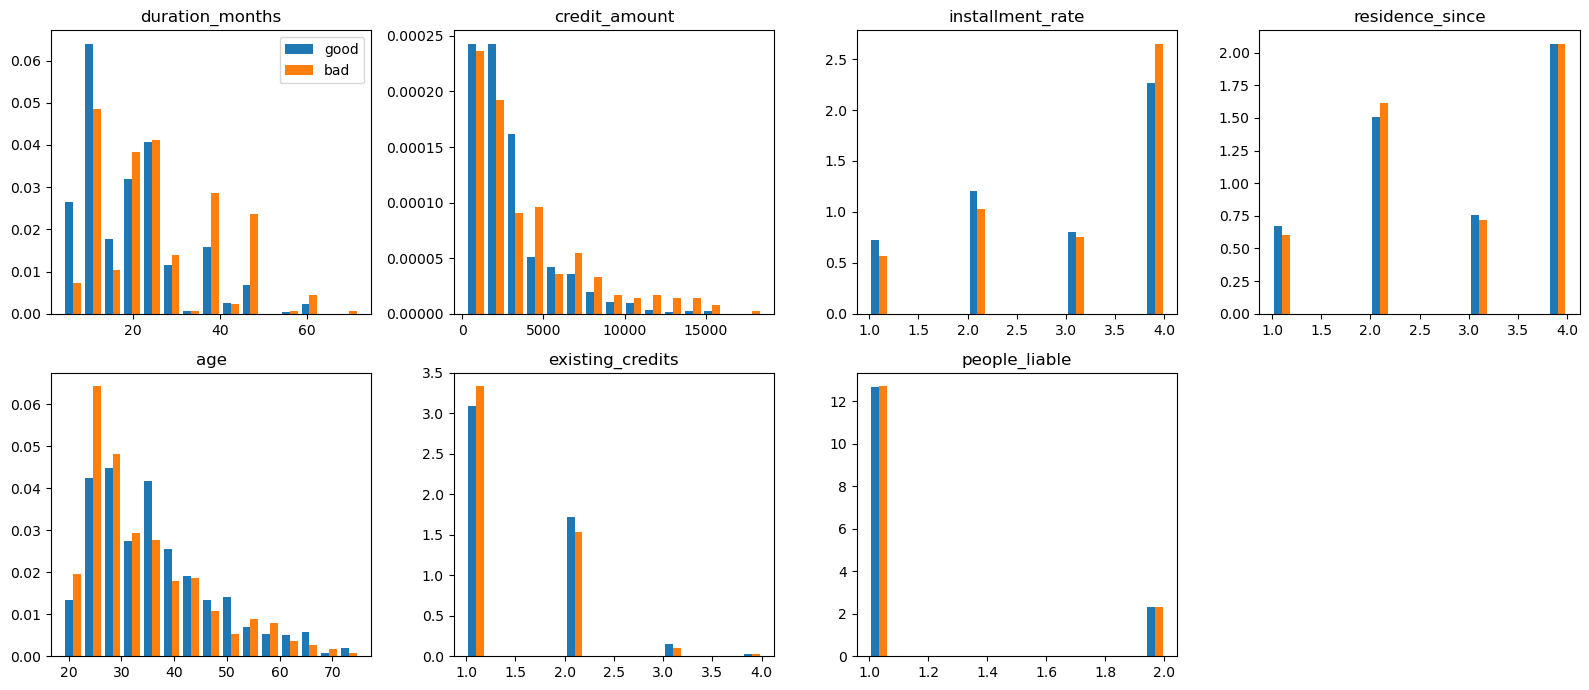

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUMERIC):
    ax.hist([X.loc[y == 0, col], X.loc[y == 1, col]],
            bins=15, label=["good", "bad"], density=True)
    ax.set_title(col)
axes.ravel()[0].legend()
for ax in axes.ravel()[len(NUMERIC):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
def bad_rate(col):
    t = y.groupby(X[col]).agg(["mean", "count"])
    t.columns = ["bad_rate", "n"]
    return t.sort_values("bad_rate", ascending=False)

for col in CATEGORICAL[:3]:
    print(col)
    display(bad_rate(col))

checking_status


,bad_rate,n
checking_status,,
A11,0.492701,274
A12,0.390335,269
A13,0.222222,63
A14,0.116751,394


credit_history


,bad_rate,n
credit_history,,
A30,0.625000,40
A31,0.571429,49
A32,0.318868,530
A33,0.318182,88
A34,0.170648,293


purpose


,bad_rate,n
purpose,,
A46,0.440000,50
A410,0.416667,12
A40,0.380342,234
A45,0.363636,22
A49,0.350515,97
A44,0.333333,12
A42,0.320442,181
A43,0.221429,280
A41,0.165049,103


In [7]:
n = len(y)
print("approve everyone:", expected_cost(y, [0] * n))
print("refuse everyone: ", expected_cost(y, [1] * n))


approve everyone: 1.5
refuse everyone:  0.7
